## Proximal gradient implementation

## Grayscale sample images at 128 × 128

Use the `camera`, `coins`, and `moon` images from
[scikit-image's sample collection](https://scikit-image.org/docs/stable/api/skimage.data.html).
These source images have more resolution than Olivetti's 64 × 64 faces.
Center-crop each image to a square, then resize with anti-aliasing and normalize
to floating-point intensities in `[0, 1]`. Select an image using `idx` below.

`image_shape = (128, 128)` is compatible with the level-3 Haar transform and
FFDNet. For other sizes, keep both dimensions divisible by 8.


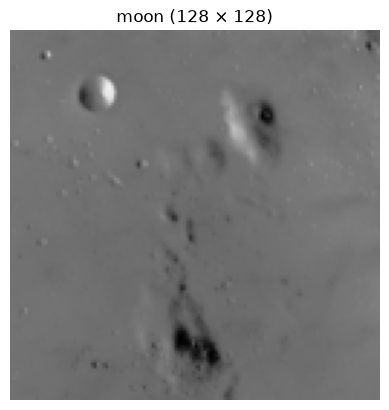

In [95]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, img_as_float
from skimage.transform import resize

image_shape = (128, 128)
image_names = ["camera", "coins", "moon"]
source_images = [data.camera(), data.coins(), data.moon()]

images = []
for image in source_images:
    # Preserve aspect ratio by center-cropping before resizing.
    height, width = image.shape
    side = min(height, width)
    top, left = (height - side) // 2, (width - side) // 2
    square = image[top:top + side, left:left + side]
    images.append(resize(img_as_float(square), image_shape, anti_aliasing=True))
images = np.stack(images)

max_n = len(images)
idx = np.random.randint(0, max_n)  # Random image on each run
x_true = images[idx]
plt.imshow(x_true, cmap="gray", vmin=0, vmax=1)
plt.title(f"{image_names[idx]} ({x_true.shape[0]} × {x_true.shape[1]})")
plt.axis("off")
plt.show()


## Blur operator

Build the periodic convolution matrix by hand, storing only the nonzero kernel
weights in SciPy's sparse CSR format. For a 128 × 128 image and a 5 × 5 kernel,
the matrix has shape `(16384, 16384)` and 409,600 nonzero entries. Its sparse
storage is about 4.75 MiB, compared with 2 GiB for a dense float64 matrix.
All restoration routines use the same `H @ x` and `H.T @ residual` operations.


In [96]:
import numpy as np

def gaussian_kernel(size=5, sigma=1.0):
    """size must be a positive odd integer."""
    assert size > 0 and size % 2 == 1
    assert sigma > 0

    coordinates = np.arange(size) - size // 2
    yy, xx = np.meshgrid(coordinates, coordinates, indexing="ij")

    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()

In [97]:
from scipy.sparse import coo_matrix


def convolution_matrix(image_shape, kernel):
    """Build a sparse periodic convolution matrix, with row-major pixels."""
    height, width = image_shape
    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1

    rows, columns, weights = [], [], []

    for i in range(height):
        for j in range(width):
            output_index = i * width + j

            for a in range(kh):
                for b in range(kw):
                    di = a - kh // 2
                    dj = b - kw // 2

                    # Input pixel contributing to output pixel (i, j)
                    input_i = (i - di) % height
                    input_j = (j - dj) % width
                    input_index = input_i * width + input_j

                    rows.append(output_index)
                    columns.append(input_index)
                    weights.append(kernel[a, b])

    # Conversion also sums duplicate entries if the kernel wraps onto itself.
    pixels = height * width
    #store the matrix in sparse representation 
    return coo_matrix(
        (weights, (rows, columns)), shape=(pixels, pixels), dtype=float
    ).tocsr()


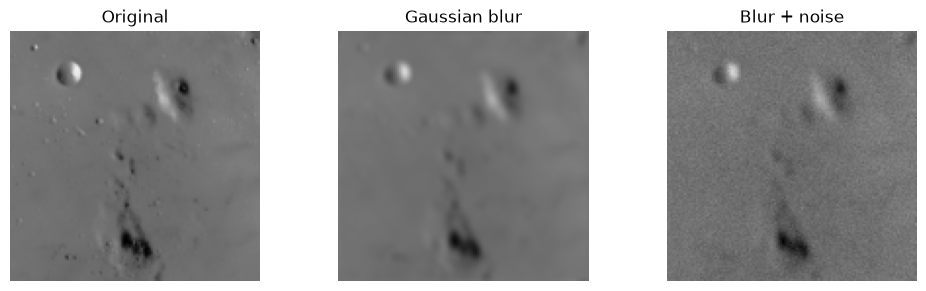

In [98]:
kernel = gaussian_kernel(size=5, sigma=2.0)
H = convolution_matrix(x_true.shape, kernel)

x_flat = x_true.ravel()
blurred = (H @ x_flat).reshape(x_true.shape)

noise_std = 0.02
rng = np.random.default_rng(42)
y = blurred + noise_std * rng.standard_normal(x_true.shape)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, image, title in zip(
    axes,
    [x_true, blurred, y],
    ["Original", "Gaussian blur", "Blur + noise"],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

First Proximal gradient we want to try is:

$$
\min_x \frac12\|Hx-y\|_2^2
      + \lambda\|x\|_1
      + \iota_{[0,1]^n}(x).
$$

Which gives the $$prox_{\gamma f}(v) = min(max(v - \gamma*\lambda, 0),1)$$

In [99]:
def restore_l1(y, H, lambd, gamma, max_iter=100, x_gt=None):
    """Minimize 0.5 * ||Hx-y||² + lambd * ||x||_1 over [0, 1].

    Use 0 < gamma <= 1 / ||H||_2² for a standard PGD step size.
    Return (flattened reconstruction, PSNR history in dB). The history
    contains one value per completed iteration, or is empty without x_gt.
    PSNR assumes ground-truth intensities in [0, 1] (data range = 1).
    """
    y = np.asarray(y, dtype=float).ravel()
    if y.size != H.shape[0]:
        raise ValueError("y must contain H.shape[0] pixels")
    if gamma <= 0 or lambd < 0 or max_iter < 0:
        raise ValueError("gamma must be positive; lambd and max_iter nonnegative")

    if x_gt is not None:
        x_gt = np.asarray(x_gt, dtype=float).ravel()
        if x_gt.size != H.shape[1]:
            raise ValueError("x_gt must contain H.shape[1] pixels")

    z_n = np.zeros(H.shape[1], dtype=float)
    psnr_history = []

    for i in range(max_iter):
        gradient = H.T @ (H @ z_n - y)
        z_n = z_n - gamma * gradient
        z_n = np.clip(z_n - gamma * lambd, 0, 1)

        if x_gt is not None:
            mse = np.mean((z_n - x_gt) ** 2)
            psnr = np.inf if mse == 0 else 10 * np.log10(1.0 / mse)
            psnr_history.append(psnr)

    return z_n, psnr_history


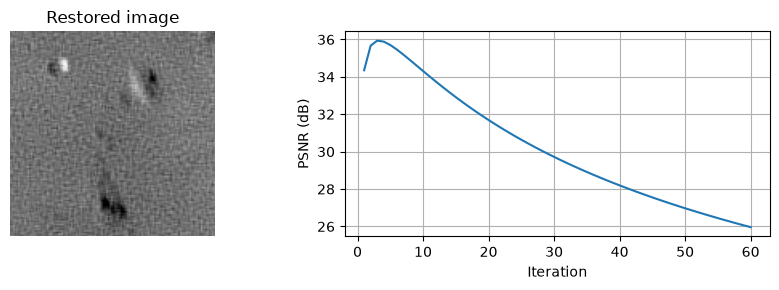

In [100]:
# For this normalized periodic Gaussian blur, ||H||_2 = 1, so gamma=1 is valid.
x_restored, psnr_history = restore_l1(
    y, H, lambd=0.001, gamma=1.0, max_iter=60, x_gt=x_true
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(x_restored.reshape(x_true.shape), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Restored image")
axes[0].axis("off")
axes[1].plot(np.arange(1, len(psnr_history) + 1), psnr_history)
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("PSNR (dB)")
axes[1].grid(True)
plt.tight_layout()
plt.show()


## Wavelet L1 reconstruction with a smoother basis

The target model is
$$
\min_x \frac12\|Hx-y\|_2^2 + \lambda\|W_{\mathrm{detail}}x\|_1.
$$
Only wavelet detail coefficients are penalized; the coarse approximation is
unchanged. For an orthonormal finite-image transform, the proximal step
transforms the image, soft-thresholds its details by $\gamma\lambda$, and
reconstructs it:
$$
v_k=x_k-\gamma H^\top(Hx_k-y),\qquad
x_{k+1}=\operatorname{prox}_{\gamma\lambda\|W_{\mathrm{detail}}\cdot\|_1}(v_k).
$$
We use [DeepInv's WaveletPrior](https://deepinv.org/api/stubs/deepinv.optim.WaveletPrior.html)
for thresholding while keeping the gradient step explicit.

The example now uses **db4**, level **3**, `lambd=0.001`, `gamma=1`, and
**70 iterations**. A smoother basis and less aggressive shrinkage reduce the
block artifacts of Haar with `lambd=0.005`. These settings were selected using
ground-truth PSNR on the 128 × 128 camera image with `noise_std=0.01`; retune
for a different image or noise level.

With db4, `mode="reflect"` extends the image at its boundaries. Transform,
threshold, and reconstruction under this extension are an approximation to
the orthonormal finite-image prox near boundaries, so this is a PGD-style
scheme rather than a claim of an exact prox for that boundary model.
For the original exact orthonormal Haar example, set `wv="haar", mode="zero"`.

There is no box constraint and we do not clip the iterates. DeepInv uses image
tensors shaped `(batch, channels, height, width)`. Image dimensions must remain
divisible by `2**level`; the blur's periodic boundaries are still defined by `H`.


In [101]:
import torch
from deepinv.optim import WaveletPrior


def restore_wavelet_l1(y, H, lambd, gamma, max_iter=70, x_gt=None, level=3,
                       wv="db4", mode="reflect"):
    """PGD-style reconstruction with DeepInv wavelet detail thresholding.

    y is a 2D grayscale image and H maps its flattened pixels to observations.
    Use 0 < gamma <= 1 / ||H||_2². Images must be divisible by 2**level.
    Return (flattened NumPy reconstruction, PSNR history in dB).
    PSNR uses data range 1; history is empty if x_gt is omitted.
    db4 reduces Haar block artifacts. Reflect padding approximates the
    orthonormal proximal step near boundaries; use haar/zero for the
    exact orthonormal case on compatible image dimensions.
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 2:
        raise ValueError("y must be a 2D grayscale image")
    if H.shape != (y.size, y.size):
        raise ValueError("H must have shape (y.size, y.size)")
    if gamma <= 0 or lambd < 0 or max_iter < 0:
        raise ValueError("gamma must be positive; lambd and max_iter nonnegative")
    if not isinstance(level, int) or level < 1:
        raise ValueError("level must be a positive integer")
    if any(size % (2**level) for size in y.shape):
        raise ValueError("image dimensions must be divisible by 2**level")

    if x_gt is not None:
        x_gt = np.asarray(x_gt, dtype=float).ravel()
        if x_gt.size != y.size:
            raise ValueError("x_gt must contain y.size pixels")

    prior = WaveletPrior(level=level, wv=wv, p=1, mode=mode, device="cpu")
    image_shape = y.shape
    y_flat = y.ravel()
    z_n = np.zeros(y.size, dtype=float)
    psnr_history = []

    with torch.no_grad():
        for i in range(max_iter):
            gradient = H.T @ (H @ z_n - y_flat)
            v = z_n - gamma * gradient

            # Add batch and channel axes for DeepInv's image-shaped prox.
            v_image = torch.from_numpy(v.reshape(1, 1, *image_shape))
            z_image = prior.prox(v_image, ths=lambd, gamma=gamma)
            z_n = z_image.numpy().reshape(-1)

            if x_gt is not None:
                mse = np.mean((z_n - x_gt) ** 2)
                psnr = np.inf if mse == 0 else 10 * np.log10(1.0 / mse)
                psnr_history.append(psnr)

    return z_n, psnr_history


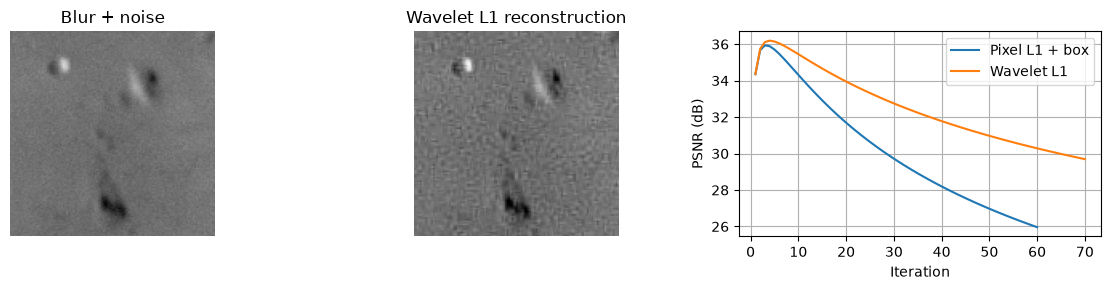

In [102]:
# Smoother db4 basis + a smaller threshold reduce Haar block artifacts.
# Tuned for camera at 128x128, noise_std=0.01; keep gamma=1 since ||H||_2=1.
x_wavelet, psnr_wavelet = restore_wavelet_l1(
    y, H, lambd=0.001, gamma=1.0, max_iter=70, x_gt=x_true,
    level=3, wv="db4", mode="reflect"
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].imshow(y, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Blur + noise")
axes[0].axis("off")
axes[1].imshow(x_wavelet.reshape(x_true.shape), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Wavelet L1 reconstruction")
axes[1].axis("off")
axes[2].plot(np.arange(1, len(psnr_history) + 1), psnr_history, label="Pixel L1 + box")
axes[2].plot(np.arange(1, len(psnr_wavelet) + 1), psnr_wavelet, label="Wavelet L1")
axes[2].set_xlabel("Iteration")
axes[2].set_ylabel("PSNR (dB)")
axes[2].legend()
axes[2].grid(True)
plt.tight_layout()
plt.show()


## PGD with total variation regularization

We solve the unconstrained problem
$$
\min_x \frac12\|Hx-y\|_2^2 + \lambda\,\mathrm{TV}(x),\qquad
\mathrm{TV}(x)=\sum_{i,j}\sqrt{(D_xx)_{i,j}^2+(D_yx)_{i,j}^2}.
$$
TV favors small spatial gradients while allowing edges. It may flatten smooth
shading and remove fine texture when the regularization is too strong.

The gradient step is still coded explicitly. The next step is
$$
x_{k+1}=\operatorname{prox}_{\gamma\lambda\mathrm{TV}}
\left(x_k-\gamma H^\top(Hx_k-y)\right).
$$
[DeepInv's TVPrior](https://deepinv.org/api/stubs/deepinv.optim.TVPrior.html)
computes this prox using an iterative inner solver. Here `gamma=gamma * lambd`
sets the full proximal weight; there is no separate `ths` argument.
`tv_max_iter` and `tv_tol` control the accuracy of that inner solver.
We impose no box constraint and do not clip the iterates.


In [103]:
import torch
from deepinv.optim import TVPrior


def restore_tv(y, H, lambd, gamma, max_iter=60, x_gt=None,
               tv_max_iter=200, tv_tol=1e-6):
    """Explicit PGD with DeepInv's isotropic TV proximal operator.

    y is a 2D grayscale image; H acts on flattened pixels.
    Use 0 < gamma <= 1 / ||H||_2² for the outer PGD step.
    Return (flattened NumPy reconstruction, PSNR history).
    PSNR assumes data range 1; history is empty without x_gt.
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 2 or H.shape != (y.size, y.size):
        raise ValueError("y must be 2D and H must have shape (y.size, y.size)")
    if gamma <= 0 or lambd < 0 or max_iter < 0:
        raise ValueError("gamma must be positive; lambd and max_iter nonnegative")
    if tv_max_iter < 1 or tv_tol <= 0:
        raise ValueError("tv_max_iter and tv_tol must be positive")
    if x_gt is not None:
        x_gt = np.asarray(x_gt, dtype=float).ravel()
        if x_gt.size != y.size:
            raise ValueError("x_gt must contain y.size pixels")

    prior = TVPrior(n_it_max=tv_max_iter, def_crit=tv_tol)
    image_shape = y.shape
    y_flat = y.ravel()
    z_n = np.zeros(y.size, dtype=float)
    psnr_history = []

    with torch.no_grad():
        for i in range(max_iter):
            gradient = H.T @ (H @ z_n - y_flat)
            v = z_n - gamma * gradient
            if lambd == 0:
                z_n = v  # Identity prox; avoid a zero-weight inner solve.
            else:
                v_image = torch.from_numpy(v.reshape(1, 1, *image_shape))
                z_image = prior.prox(v_image, gamma=gamma * lambd)
                z_n = z_image.numpy().reshape(-1)

            if x_gt is not None:
                mse = np.mean((z_n - x_gt) ** 2)
                psnr_history.append(np.inf if mse == 0 else -10 * np.log10(mse))

    return z_n, psnr_history


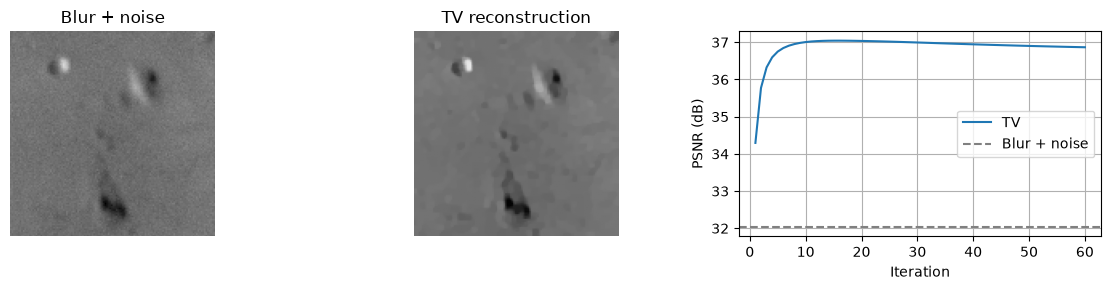

In [104]:
# Tune lambd independently for TV, e.g. 0.001, 0.003, 0.01, 0.03.
x_tv, psnr_tv = restore_tv(
    y, H, lambd=0.003, gamma=1.0, max_iter=60, x_gt=x_true
)

mse_input = np.mean((y - x_true) ** 2)
psnr_input = np.inf if mse_input == 0 else -10 * np.log10(mse_input)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, image, title in zip(
    axes[:2], [y, x_tv.reshape(x_true.shape)], ["Blur + noise", "TV reconstruction"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
axes[2].plot(np.arange(1, len(psnr_tv) + 1), psnr_tv, label="TV")
axes[2].axhline(psnr_input, color="gray", linestyle="--", label="Blur + noise")
axes[2].set_xlabel("Iteration")
axes[2].set_ylabel("PSNR (dB)")
axes[2].legend()
axes[2].grid(True)
plt.tight_layout()
plt.show()


## Plug-and-play gradient descent with a pretrained denoiser

Replace the proximal step by a denoising step:
$$
v_k=x_k-\gamma H^\top(Hx_k-y),\qquad
x_{k+1}=D_{\sigma_{\mathrm{den}}}(v_k).
$$
We use [DeepInv's PnP wrapper](https://deepinv.org/api/stubs/deepinv.optim.PnP.html)
with a pretrained grayscale
[FFDNet](https://deepinv.org/api/stubs/deepinv.models.FFDNet.html).
The gradient update and outer iteration remain explicit. Unlike TV PGD, this
scheme generally has no known explicit regularization objective; the PGD step
size bound alone does not guarantee convergence for an arbitrary denoiser.

`sigma_denoiser` controls the denoising strength on the `[0, 1]` intensity scale.
It is a tuning parameter, not necessarily equal to the measurement `noise_std`,
and is passed directly to `PnP.prox`, without multiplication by `gamma`.
The example uses `sigma_denoiser=0.015`, `gamma=1`, **40 iterations**, and
**16-pixel reflected padding** around the denoiser input, cropped after each
call. Padding reduces the effect of FFDNet's convolution boundaries when
applied repeatedly; it does not change `H` or the observation model.
The original `sigma_denoiser=0.01` with a longer run lost substantial PSNR.
These settings were selected using ground-truth PSNR on the camera example
with `noise_std=0.01`; they are not a universal convergence guarantee.
Use `denoiser_padding=0` to compare the original denoising step.
We do not clip the iterates, and PSNR is measured on the unmodified estimates.

The model-loading cell downloads pretrained weights on first use and caches
those weights via PyTorch. The network runs in evaluation mode without gradients.


In [105]:
from deepinv.optim import PnP
from deepinv.models import FFDNet


def restore_pnp(y, H, denoiser, gamma, sigma_denoiser=0.015,
                max_iter=40, x_gt=None, device="cpu", denoiser_padding=16):
    """Explicit PnP gradient descent using a DeepInv denoiser.

    Return (flattened NumPy reconstruction, PSNR history).
    PSNR assumes data range 1; history is empty without x_gt.
    Neural denoising runs in float32 on the selected device.
    Reflect-padding the denoiser input reduces repeated border artifacts.
    denoiser_padding=0 recovers the original unpadded denoising step.
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 2 or H.shape != (y.size, y.size):
        raise ValueError("y must be 2D and H must have shape (y.size, y.size)")
    if gamma <= 0 or sigma_denoiser < 0 or max_iter < 0:
        raise ValueError("gamma must be positive; sigma_denoiser and max_iter nonnegative")
    if (not isinstance(denoiser_padding, int) or denoiser_padding < 0
            or denoiser_padding % 2 or denoiser_padding >= min(y.shape)):
        raise ValueError("denoiser_padding must be an even integer in [0, min(y.shape))")
    if x_gt is not None:
        x_gt = np.asarray(x_gt, dtype=float).ravel()
        if x_gt.size != y.size:
            raise ValueError("x_gt must contain y.size pixels")

    prior = PnP(denoiser=denoiser).to(device=device, dtype=torch.float32).eval()
    image_shape = y.shape
    y_flat = y.ravel()
    z_n = np.zeros(y.size, dtype=float)
    psnr_history = []

    with torch.no_grad():
        for i in range(max_iter):
            gradient = H.T @ (H @ z_n - y_flat)
            v = z_n - gamma * gradient
            v_image = torch.as_tensor(
                v.reshape(1, 1, *image_shape), dtype=torch.float32, device=device
            )
            # Pad only for denoising; H keeps its original boundary convention.
            pad = denoiser_padding
            if pad:
                v_image = torch.nn.functional.pad(
                    v_image, (pad, pad, pad, pad), mode="reflect"
                )
            z_image = prior.prox(v_image, sigma_denoiser=sigma_denoiser)
            if pad:
                z_image = z_image[..., pad:-pad, pad:-pad]
            z_n = z_image.cpu().numpy().reshape(-1)

            if x_gt is not None:
                mse = np.mean((z_n - x_gt) ** 2)
                psnr_history.append(np.inf if mse == 0 else -10 * np.log10(mse))

    return z_n, psnr_history


In [106]:
# Run this cell once; reuse the pretrained denoiser when tuning parameters.
# FFDNet defaults match the downloadable grayscale network.
denoiser = FFDNet(img_channels=1, pretrained="download", device="cpu").eval()


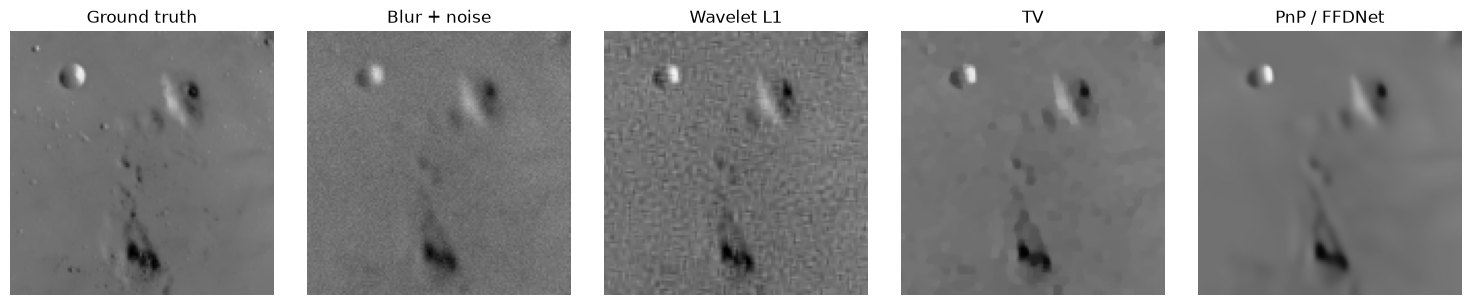

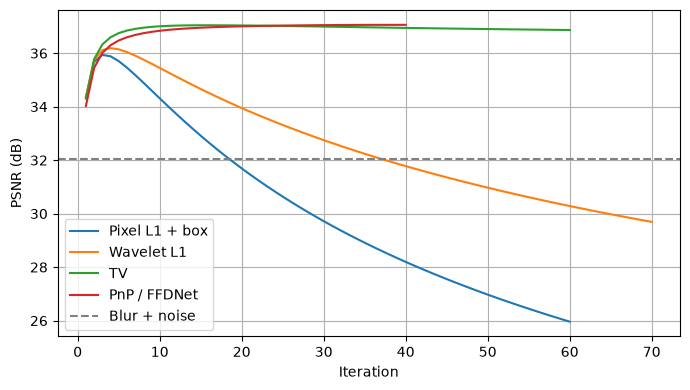

Blur + noise: 32.03 dB
Pixel L1 + box: final 25.96 dB; best 35.94 dB at iteration 3
Wavelet L1: final 29.69 dB; best 36.19 dB at iteration 4
TV: final 36.87 dB; best 37.04 dB at iteration 16
PnP / FFDNet: final 37.06 dB; best 37.06 dB at iteration 39


In [107]:
# Tuned for camera, noise_std=0.01: stronger denoising and a shorter run.
x_pnp, psnr_pnp = restore_pnp(
    y, H, denoiser, gamma=1.0, sigma_denoiser=0.015,
    max_iter=40, x_gt=x_true, denoiser_padding=16
)

# Same observation and display range for all methods; no clipping of estimates.
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, image, title in zip(
    axes,
    [x_true, y, x_wavelet.reshape(x_true.shape),
     x_tv.reshape(x_true.shape), x_pnp.reshape(x_true.shape)],
    ["Ground truth", "Blur + noise", "Wavelet L1", "TV", "PnP / FFDNet"],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

histories = {
    "Pixel L1 + box": psnr_history,
    "Wavelet L1": psnr_wavelet,
    "TV": psnr_tv,
    "PnP / FFDNet": psnr_pnp,
}
fig, ax = plt.subplots(figsize=(7, 4))
for label, history in histories.items():
    ax.plot(np.arange(1, len(history) + 1), history, label=label)
ax.axhline(psnr_input, color="gray", linestyle="--", label="Blur + noise")
ax.set_xlabel("Iteration")
ax.set_ylabel("PSNR (dB)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Blur + noise: {psnr_input:.2f} dB")
for label, history in histories.items():
    if history:
        best_iteration = int(np.argmax(history)) + 1
        print(f"{label}: final {history[-1]:.2f} dB; "
              f"best {max(history):.2f} dB at iteration {best_iteration}")
# Best-iteration values use ground truth for diagnostics, not a practical stopping rule.
